# Exploratory Data Analysis — Retail Sales Data
**OASIS INFOBYTE · Data Analytics · Level 1 · Task 1**

**Objective:** explore a retail sales dataset to uncover sales patterns, customer behaviour and actionable business insights.

**Dataset:** `retail_sales_dataset.csv` — 1,000 transactions (Jan 2023 – Jan 2024) with columns: Transaction ID, Date, Customer ID, Gender, Age, Product Category, Quantity, Price per Unit, Total Amount.

**Notebook outline**
1. Data loading, inspection and quality checks
2. Descriptive statistics
3. Overall sales performance
4. Time series analysis (monthly and quarterly)
5. Customer demographics (age group, gender)
6. Product analysis (category and price point)
7. Correlation heatmap
8. Additional insight: age group x category
9. Conclusions and business recommendations

In [21]:
import os
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.float_format", "{:,.2f}".format)
os.makedirs("figures", exist_ok=True)

df = pd.read_csv("retail_sales_dataset.csv")
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## 1. Data loading and inspection
First look at the structure of the data: size, column types and missing values.

In [22]:
print("Shape (rows, columns):", df.shape)
print("\nColumn data types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isna().sum())

Shape (rows, columns): (1000, 9)

Column data types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Missing values per column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [23]:
# Convert Date from text to datetime, then run data quality checks
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

expected_amount = df["Quantity"] * df["Price per Unit"]

print("Duplicate transaction IDs:        ", df["Transaction ID"].duplicated().sum())
print("Invalid / missing dates:          ", df["Date"].isna().sum())
print("Invalid ages (<0 or >120):        ", ((df["Age"] < 0) | (df["Age"] > 120)).sum())
print("Zero or negative quantities:      ", (df["Quantity"] <= 0).sum())
print("Zero or negative prices:          ", (df["Price per Unit"] <= 0).sum())
print("Zero or negative total amounts:   ", (df["Total Amount"] <= 0).sum())
print("Total != Quantity x Price rows:   ", (df["Total Amount"] != expected_amount).sum())

print("\nProduct categories:")
print(df["Product Category"].value_counts())
print("\nGender values:")
print(df["Gender"].value_counts())
print("\nDate range:", df["Date"].min().date(), "to", df["Date"].max().date())

Duplicate transaction IDs:         0
Invalid / missing dates:           0
Invalid ages (<0 or >120):         0
Zero or negative quantities:       0
Zero or negative prices:           0
Zero or negative total amounts:    0
Total != Quantity x Price rows:    0

Product categories:
Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64

Gender values:
Gender
Female    510
Male      490
Name: count, dtype: int64

Date range: 2023-01-01 to 2024-01-01


In [24]:
# The data runs to 1 Jan 2024 - check how much of January 2024 is actually present
january_2024 = df[df["Date"].dt.to_period("M") == "2024-01"]
print("Records in January 2024:", len(january_2024))
january_2024

Records in January 2024: 2


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
210,211,2024-01-01,CUST211,Male,42,Beauty,3,500,1500
649,650,2024-01-01,CUST650,Male,55,Electronics,1,30,30


### Observations — data quality
- The dataset is **clean**: no missing values, no duplicate transaction IDs, no invalid dates, ages, quantities or prices, and `Total Amount` always equals `Quantity x Price per Unit`. No imputation or row removal was needed.
- Categories (Clothing, Electronics, Beauty) and genders (Female, Male) are consistently labelled.
- **Caveat:** January 2024 contains only **2 transactions** (all dated 1 Jan 2024). It is not a full month, so it is **excluded from the time-series charts** below to avoid showing a misleading "collapse" in sales.

## 2. Descriptive statistics
Mean, median, mode and standard deviation for every numerical column.

In [25]:
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]

stats = pd.DataFrame({
    "Mean": df[num_cols].mean(),
    "Median": df[num_cols].median(),
    "Mode": df[num_cols].mode().iloc[0],
    "Std Dev": df[num_cols].std(),
    "Min": df[num_cols].min(),
    "Max": df[num_cols].max(),
})
stats

,Mean,Median,Mode,Std Dev,Min,Max
Age,41.39,42.00,43.00,13.68,18,64
Quantity,2.51,3.00,4.00,1.13,1,4
Price per Unit,179.89,50.00,50.00,189.68,25,500
Total Amount,456.00,135.00,50.00,560.00,25,2000


In [26]:
print("Distinct Price per Unit values:", sorted(df["Price per Unit"].unique()))
print("Distinct Quantity values:      ", sorted(df["Quantity"].unique()))

Distinct Price per Unit values: [np.int64(25), np.int64(30), np.int64(50), np.int64(300), np.int64(500)]
Distinct Quantity values:       [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


### Observations — descriptive statistics
- `Price per Unit` and `Quantity` take only a **small set of discrete values** (printed above), so they behave more like categories than continuous variables.
- Because `Total Amount = Quantity x Price per Unit`, its spread is driven by which price point is bought and in what quantity. Compare the **mean and median** in the table: a mean noticeably above the median means a minority of high-value purchases pull the average up.
- The overall average transaction is **456**, a useful benchmark for the segment comparisons later in this notebook.
- Check the `Age` row for the customer age range and its mean.

## 3. Overall sales performance
Headline KPIs, followed by revenue broken down by category, gender and age group.

In [27]:
total_revenue = df["Total Amount"].sum()
total_transactions = df["Transaction ID"].nunique()
average_transaction = df["Total Amount"].mean()
total_items = df["Quantity"].sum()

print(f"Total revenue:              {total_revenue:,.2f}")
print(f"Total transactions:         {total_transactions:,}")
print(f"Average transaction amount: {average_transaction:,.2f}")
print(f"Total items sold:           {total_items:,}")
print(f"Unique customers:           {df['Customer ID'].nunique():,}")

Total revenue:              456,000.00
Total transactions:         1,000
Average transaction amount: 456.00
Total items sold:           2,514
Unique customers:           1,000


In [28]:
# Derived columns used throughout the analysis
df["Month"] = df["Date"].dt.to_period("M")
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65"],
)

category_sales = (
    df.groupby("Product Category")
    .agg(Revenue=("Total Amount", "sum"),
         Transactions=("Transaction ID", "nunique"),
         Items_Sold=("Quantity", "sum"),
         Avg_Transaction=("Total Amount", "mean"))
    .sort_values("Revenue", ascending=False)
)
category_sales["Revenue Share %"] = category_sales["Revenue"] / total_revenue * 100

gender_sales = (
    df.groupby("Gender")
    .agg(Total_Revenue=("Total Amount", "sum"),
         Transactions=("Transaction ID", "nunique"),
         Average_Transaction=("Total Amount", "mean"))
)

age_sales = (
    df.groupby("Age Group", observed=False)["Total Amount"]
    .agg(["sum", "count", "mean"])
    .rename(columns={"sum": "Total Revenue", "count": "Transactions", "mean": "Average Transaction"})
)

print("SALES BY CATEGORY"); print(category_sales)
print("\nSALES BY GENDER");  print(gender_sales)
print("\nSALES BY AGE GROUP"); print(age_sales)

SALES BY CATEGORY
                  Revenue  Transactions  Items_Sold  Avg_Transaction  \
Product Category                                                       
Electronics        156905           342         849           458.79   
Clothing           155580           351         894           443.25   
Beauty             143515           307         771           467.48   

                  Revenue Share %  
Product Category                   
Electronics                 34.41  
Clothing                    34.12  
Beauty                      31.47  

SALES BY GENDER
        Total_Revenue  Transactions  Average_Transaction
Gender                                                  
Female         232840           510               456.55
Male           223160           490               455.43

SALES BY AGE GROUP
           Total Revenue  Transactions  Average Transaction
Age Group                                                  
18-25              84550           169               500

## 4. Time series analysis
Monthly and quarterly revenue for 2023 (the only complete calendar year in the data).

MONTHLY REVENUE (2023)
Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
Freq: M, Name: Total Amount, dtype: int64

QUARTERLY REVENUE (2023)
        Revenue  Transactions  Avg_Transaction
Date                                          
2023Q1   108500           234           463.68
2023Q2   123735           268           461.70
2023Q3    96045           231           415.78
2023Q4   126190           265           476.19


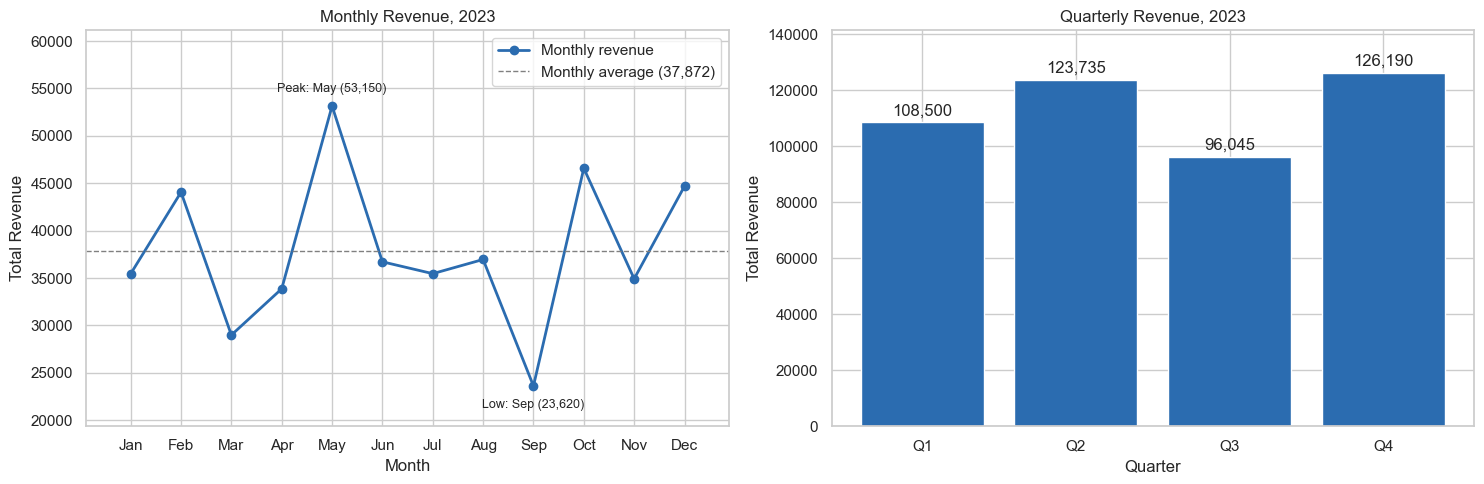

In [29]:
df_2023 = df[df["Date"].dt.year == 2023]

monthly_sales = df_2023.groupby(df_2023["Date"].dt.to_period("M"))["Total Amount"].sum()
quarterly_sales = (
    df_2023.groupby(df_2023["Date"].dt.to_period("Q"))["Total Amount"]
    .agg(Revenue="sum", Transactions="count", Avg_Transaction="mean")
)
print("MONTHLY REVENUE (2023)"); print(monthly_sales)
print("\nQUARTERLY REVENUE (2023)"); print(quarterly_sales)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Monthly line chart
m = monthly_sales.copy()
m.index = m.index.strftime("%b")
m.plot(kind="line", marker="o", ax=axes[0], color="#2b6cb0", linewidth=2, label="Monthly revenue")
axes[0].set_xticks(range(len(m)))
axes[0].set_xticklabels(m.index)
axes[0].margins(x=0.08)
axes[0].set_ylim(m.min() * 0.82, m.max() * 1.15)
axes[0].axhline(m.mean(), color="grey", linestyle="--", linewidth=1, label=f"Monthly average ({m.mean():,.0f})")
axes[0].annotate(f"Peak: {m.idxmax()} ({m.max():,.0f})", (list(m.index).index(m.idxmax()), m.max()),
                 textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
axes[0].annotate(f"Low: {m.idxmin()} ({m.min():,.0f})", (list(m.index).index(m.idxmin()), m.min()),
                 textcoords="offset points", xytext=(0, -16), ha="center", fontsize=9)
axes[0].set_title("Monthly Revenue, 2023")
axes[0].set_xlabel("Month"); axes[0].set_ylabel("Total Revenue")
axes[0].legend()

# Quarterly bar chart
q = quarterly_sales["Revenue"].copy()
q.index = [f"Q{p.quarter}" for p in q.index]
bars = axes[1].bar(q.index, q.values, color="#2b6cb0")
axes[1].bar_label(bars, labels=[f"{v:,.0f}" for v in q.values], padding=3)
axes[1].set_title("Quarterly Revenue, 2023")
axes[1].set_xlabel("Quarter"); axes[1].set_ylabel("Total Revenue")
axes[1].set_ylim(0, q.max() * 1.12)

plt.tight_layout()
plt.savefig("figures/time_series.png", dpi=300, bbox_inches="tight")
plt.show()

### Observations — time series
- Revenue is **volatile month to month** rather than steadily growing: **May is the peak (53,150)** and **September is the low (23,620)**, less than half the May figure.
- A second strong period appears at the end of the year: **October (46,580)** and **December (44,690)** are both well above the monthly average, while November dips back.
- By quarter, **Q4 (126,190) and Q2 (123,735)** are the strongest, **Q1 (108,500)** is mid-range and **Q3 (96,045)** is the weakest, dragged down by September.
- There is no clear upward trend across 2023, so growth will have to come from marketing and mix rather than momentum.

## 5. Customer demographics
Who is buying? Age distribution, gender split and spending by age group.

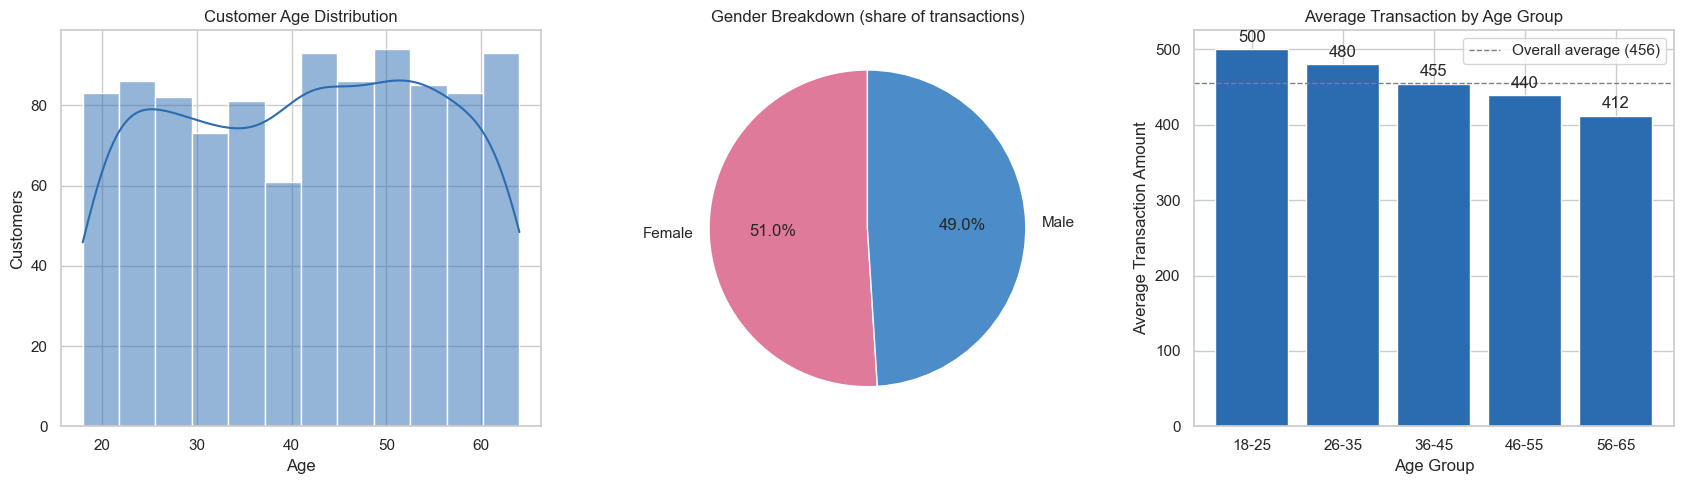

        Total_Revenue  Transactions  Average_Transaction
Gender                                                  
Female         232840           510               456.55
Male           223160           490               455.43

           Total Revenue  Transactions  Average Transaction
Age Group                                                  
18-25              84550           169               500.30
26-35              98480           205               480.39
36-45              91870           202               454.80
46-55             100690           229               439.69
56-65              80410           195               412.36


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Age distribution
sns.histplot(df["Age"], bins=12, kde=True, ax=axes[0], color="#2b6cb0")
axes[0].set_title("Customer Age Distribution")
axes[0].set_xlabel("Age"); axes[0].set_ylabel("Customers")

# Gender breakdown
gender_counts = df["Gender"].value_counts()
axes[1].pie(gender_counts, labels=gender_counts.index, autopct="%1.1f%%", startangle=90,
            colors=["#e07a9a", "#4c8dc9"], wedgeprops={"edgecolor": "white"})
axes[1].set_title("Gender Breakdown (share of transactions)")

# Average transaction by age group
avg_age = age_sales["Average Transaction"]
bars = axes[2].bar(avg_age.index.astype(str), avg_age.values, color="#2b6cb0")
axes[2].bar_label(bars, labels=[f"{v:,.0f}" for v in avg_age.values], padding=3)
axes[2].axhline(average_transaction, color="grey", linestyle="--", linewidth=1,
                label=f"Overall average ({average_transaction:,.0f})")
axes[2].set_title("Average Transaction by Age Group")
axes[2].set_xlabel("Age Group"); axes[2].set_ylabel("Average Transaction Amount")
axes[2].legend()

plt.tight_layout()
plt.savefig("figures/demographics.png", dpi=300, bbox_inches="tight")
plt.show()

print(gender_sales)
print()
print(age_sales)

### Observations — demographics
- **Gender is balanced**: 510 female vs 490 male transactions, and revenue of 232,840 vs 223,160. The average transaction is almost identical (about 456.5 vs 455.4), so gender is **not a useful differentiator** for spending behaviour.
- **Age tells a more interesting story.** The **46-55 group is the largest by revenue (100,690) and transaction count (229)**, yet the **18-25 group spends the most per transaction (about 500)**. Average spend then falls steadily with age, down to about 412 for the 56-65 group.
- In short: older customers buy more often in total volume, younger customers spend more each time they buy.

## 6. Product analysis
The dataset has **no product-name column**, so the "top 10 best-selling products" analysis is done at the two product levels that exist: **Product Category** and **Price per Unit** (price point).

TOP PRICE POINTS (up to 10) BY REVENUE
                Revenue  Transactions  Units_Sold  Revenue Share %
Price per Unit                                                    
500              247500           199         495            54.28
300              155400           197         518            34.08
50                26700           211         534             5.86
30                13350           183         445             2.93
25                13050           210         522             2.86

CATEGORY PERFORMANCE
                  Revenue  Transactions  Items_Sold  Avg_Transaction  \
Product Category                                                       
Electronics        156905           342         849           458.79   
Clothing           155580           351         894           443.25   
Beauty             143515           307         771           467.48   

                  Revenue Share %  
Product Category                   
Electronics                 34.41  
C

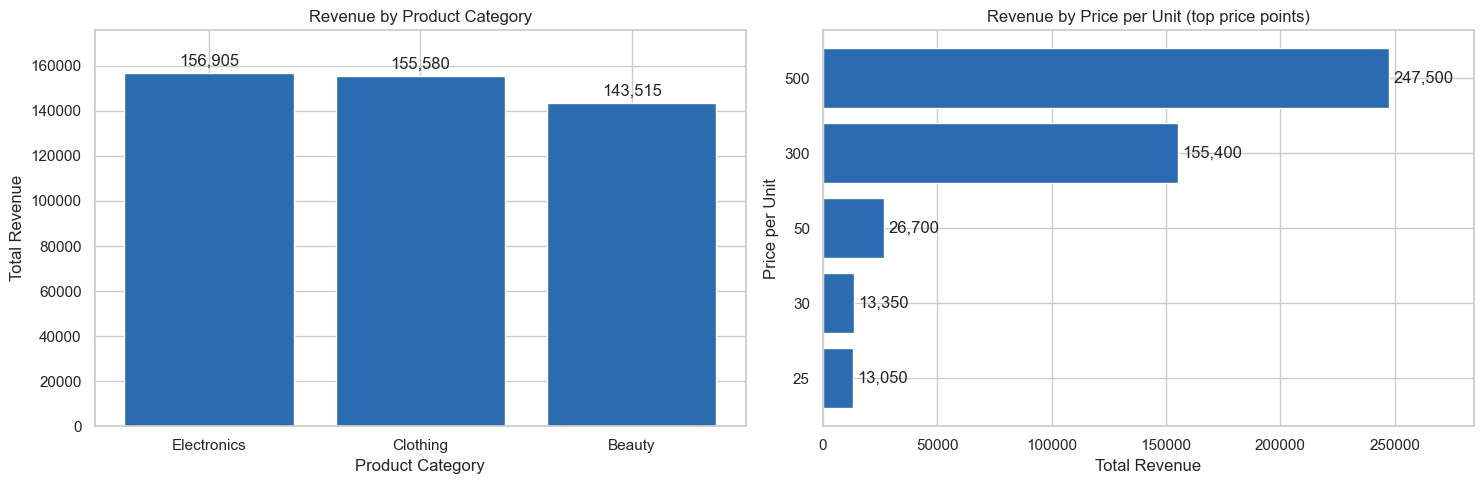

In [31]:
price_perf = (
    df.groupby("Price per Unit")
    .agg(Revenue=("Total Amount", "sum"),
         Transactions=("Transaction ID", "count"),
         Units_Sold=("Quantity", "sum"))
    .sort_values("Revenue", ascending=False)
    .head(10)
)
price_perf["Revenue Share %"] = price_perf["Revenue"] / total_revenue * 100

print("TOP PRICE POINTS (up to 10) BY REVENUE"); print(price_perf)
print("\nCATEGORY PERFORMANCE"); print(category_sales)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Revenue by category
bars = axes[0].bar(category_sales.index, category_sales["Revenue"], color="#2b6cb0")
axes[0].bar_label(bars, labels=[f"{v:,.0f}" for v in category_sales["Revenue"]], padding=3)
axes[0].set_title("Revenue by Product Category")
axes[0].set_xlabel("Product Category"); axes[0].set_ylabel("Total Revenue")
axes[0].set_ylim(0, category_sales["Revenue"].max() * 1.12)

# Revenue by price point
pp = price_perf.sort_values("Revenue")
bars = axes[1].barh(pp.index.astype(str), pp["Revenue"], color="#2b6cb0")
axes[1].bar_label(bars, labels=[f"{v:,.0f}" for v in pp["Revenue"]], padding=3)
axes[1].set_title("Revenue by Price per Unit (top price points)")
axes[1].set_xlabel("Total Revenue"); axes[1].set_ylabel("Price per Unit")
axes[1].set_xlim(0, pp["Revenue"].max() * 1.15)

plt.tight_layout()
plt.savefig("figures/product_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

### Observations — products
- **Revenue is split almost evenly across the three categories**: Electronics 156,905 (34.4%), Clothing 155,580 (34.1%) and Beauty 143,515 (31.5%).
- The mix behind those numbers differs: **Clothing leads on transactions (351) and items sold (894)**, while **Electronics earns its lead from a higher value per sale** (only 342 transactions). **Beauty is last on all three measures.**
- The price-point table and chart compare each price point's **share of revenue** with its **share of transactions**; where the revenue share is larger, those items are disproportionately valuable and worth protecting in stock and promotions.

## 7. Correlation heatmap
Pairwise correlation between the numerical variables.

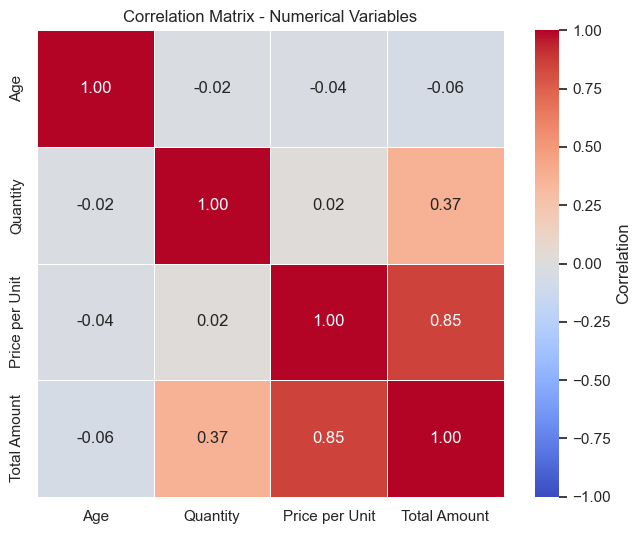

Strongest relationships:
Price per Unit  Total Amount      0.85
Quantity        Total Amount      0.37
Age             Total Amount     -0.06
                Price per Unit   -0.04
                Quantity         -0.02
Quantity        Price per Unit    0.02
dtype: float64


In [32]:
corr = df[num_cols].corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Correlation"})
plt.title("Correlation Matrix - Numerical Variables")
plt.tight_layout()
plt.savefig("figures/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(key=abs, ascending=False)
print("Strongest relationships:")
print(pairs)

### Observations — correlation
- `Total Amount` correlates most strongly with `Price per Unit` and `Quantity`. That is expected, since it is calculated from them, so it is not an independent finding.
- Read the `Age` row in the heatmap: if its correlations with spending are close to zero, the age pattern in section 5 is a **modest group-level trend**, not a strong predictor of an individual transaction's value.
- Likewise, a correlation near zero between `Quantity` and `Price per Unit` means customers do not systematically buy more units of cheaper items.

## 8. Additional insight — which age groups buy which categories?
A cross-tab of **age group x product category** reveals where revenue is concentrated, something the separate category and age charts cannot show.

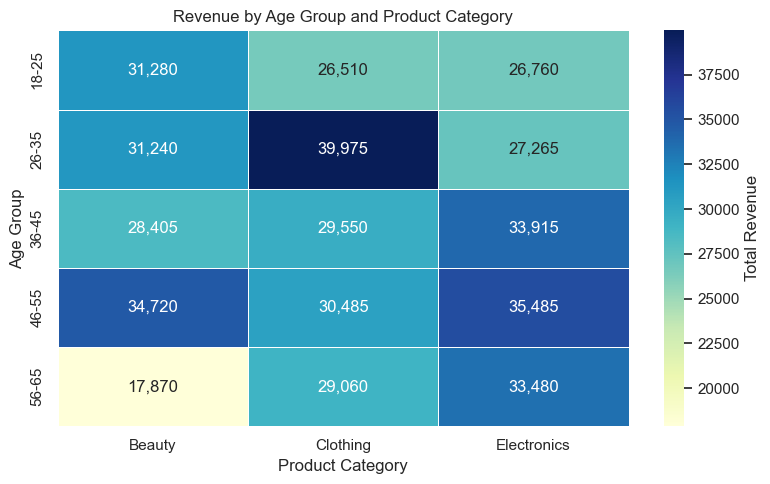

Top 3 age group / category combinations by revenue:
Product Category  Age Group
Clothing          26-35        39975
Electronics       46-55        35485
Beauty            46-55        34720
dtype: int64

Bottom 3:
Product Category  Age Group
Electronics       18-25        26760
Clothing          18-25        26510
Beauty            56-65        17870
dtype: int64


In [33]:
pivot = df.pivot_table(index="Age Group", columns="Product Category", values="Total Amount",
                       aggfunc="sum", observed=False)

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="YlGnBu", linewidths=0.5,
            cbar_kws={"label": "Total Revenue"})
plt.title("Revenue by Age Group and Product Category")
plt.tight_layout()
plt.savefig("figures/age_category_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

combos = pivot.unstack().sort_values(ascending=False)
print("Top 3 age group / category combinations by revenue:")
print(combos.head(3))
print("\nBottom 3:")
print(combos.tail(3))

### Observations — age x category
- Spending is **not evenly spread** across the grid: a handful of age-group/category combinations account for noticeably more revenue than others (see the top and bottom combinations printed above).
- This means category promotions should be **targeted by age group** instead of run store-wide - the strongest segments deserve retention offers, and the weakest cells are the clearest opportunity for growth campaigns.

## 9. Conclusions and business recommendations

**Summary:** 1,000 transactions generated **456,000 in revenue** (average transaction 456, 2,514 items sold) with a clean, consistent dataset.

### Actionable recommendations
1. **Plan around seasonality.** Revenue peaks in May (53,150) and again in October-December, and falls sharply in September (23,620, less than half of May). Build inventory and staffing ahead of those peaks, and run targeted promotions or loyalty offers in September and Q3 to lift the weakest period.
2. **Segment marketing by age, not gender.** Gender shows no meaningful spending difference (average transaction about 456 for both). Age does: 18-25 customers spend about 500 per transaction while the 56-65 group spends about 412. Use **premium and high-value offers for younger customers** and **frequency / loyalty and bundle offers for the 46-55 group**, which is the largest by revenue and transaction count.
3. **Grow Beauty through cross-selling and bundling.** Beauty is last on revenue (143,515), transactions (307) and items sold (771). Pairing it with Clothing and Electronics purchases is the quickest way to close the gap. For Electronics, which earns its lead through value per sale, protect margin and upsell on price point; for Clothing, which leads on volume, focus on basket size.
4. **Use the age x category view to target campaigns.** Concentrate category promotions on the age groups that already over-index, and test growth campaigns in the weakest cells (section 8).

### Limitations
- Only one year of data, and January 2024 is a single day, so seasonal patterns are indicative rather than proven.
- No product-name, store or channel information, so product analysis is limited to category and price point.
- `Customer ID` is effectively one transaction per customer, so repeat-purchase behaviour (retention, lifetime value) cannot be analysed here.